# 7CS537 CW2, Notebook 06: Hybrid alert triage and explanations

**Student number:** 100810453

**Purpose:** turn the two detectors into the CW2 artefact's core: a single ranked alert queue for TeleComNet's SOC, where every alert has a priority and an explanation an analyst can act on.

**Why this step is needed:** Notebooks 04 and 05 showed:
- XGBoost raises very few false alarms but misses new attack families (0.12% on Friday).
- The autoencoder catches some new attacks (78.4% of new DoS on Wednesday) but on Friday raised 26,485 false alarms in one day, because normal traffic drifted.
- Alerting on either model would give about 50,700 Friday alerts, roughly half false. No SOC team can review that many by hand.

So the question is no longer only "which flows are attacks?" but "which alerts should an analyst look at first, given limited time?". This notebook answers it with three steps:
1. **Priority tiers:** P1 when both models flag a flow, P2 when only XGBoost does, P3 when only the autoencoder does.
2. **A daily alert queue capped at analyst capacity** (for example the top 1,000 alerts a day), and how many real attacks reach it.
3. **Explanations** for each alert: the features that pushed XGBoost's score up, and the features the autoencoder rebuilt worst.

**Why this tier order:** it was fixed before looking at test results. A match to a known attack pattern (XGBoost) is more specific than "this looks unusual" (autoencoder). When both agree, the evidence is strongest.

**Inputs:** CW1 data and features; Notebook 03 splits; Notebook 04 scores and models; Notebook 05 scores, thresholds, preprocessing and autoencoder weights.

**Outputs:** `cw2/outputs/06_*`; `cw2/data/06_alert_queue.parquet` (ranked queues with explanations, used by the dashboard).

**How to run:** after Notebooks 04 and 05, from the repository folder: `jupyter nbconvert --to notebook --execute --inplace cw2/06_hybrid_triage.ipynb`. PyTorch is **not** imported here (it crashes alongside XGBoost on macOS); the autoencoder's weights are converted to NumPy in a separate process.

## 1. Setup

In [1]:
import os
import sys
import json
import hashlib
import platform
import subprocess

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import joblib
import sklearn
import xgboost as xgb
from xgboost import XGBClassifier

try:
    from IPython.display import display
except ImportError:
    display = print

RANDOM_STATE = 42
TARGET_FPR = 0.01
CAPACITIES = [500, 1000, 5000]       # alerts an analyst team could review per day
MAIN_CAPACITY = 1000
QUEUE_SAVE = 5000                    # alerts per day saved with explanations for the dashboard
TOP_FEATURES = 3
DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
TEST_DAYS = {"Wednesday": "E2_Wednesday", "Thursday": "E2_Thursday", "Friday": "E1"}   # day -> XGBoost experiment

ROOT = ".." if os.path.exists(os.path.join("..", "outputs", "01_feature_list.txt")) else "."
DATA_FILE = os.path.join(ROOT, "data", "cicids2017_clean.parquet")
CW1_OUT = os.path.join(ROOT, "outputs")
CW2_DIR = os.path.join(ROOT, "cw2")
OUT_DIR = os.path.join(CW2_DIR, "outputs")
MODEL_DIR = os.path.join(CW2_DIR, "models")
QUEUE_FILE = os.path.join(CW2_DIR, "data", "06_alert_queue.parquet")
print("xgboost", xgb.__version__, "| scikit-learn", sklearn.__version__, "| numpy", np.__version__)

xgboost 3.4.1 | scikit-learn 1.9.1 | numpy 2.5.4


## 2. Load data, splits and saved scores

In [2]:
if os.path.exists(DATA_FILE):
    df = pd.read_parquet(DATA_FILE)
else:
    df = pd.read_pickle(DATA_FILE.replace(".parquet", ".pkl"))
for col in ["Label", "attack_family", "source_file"]:
    df[col] = df[col].astype(str)
with open(os.path.join(CW1_OUT, "01_feature_list.txt")) as fh:
    feature_cols = [line.strip() for line in fh if line.strip()]
with open(os.path.join(OUT_DIR, "03_run_config.json")) as fh:
    nb03 = json.load(fh)
h = pd.util.hash_pandas_object(df[["Label", "source_file"]], index=False).to_numpy()
fingerprint = hashlib.sha256(h.tobytes()).hexdigest()[:16]
assert fingerprint == nb03["data_fingerprint"], "Data differs from Notebook 03; re-run Notebook 03"

splits = pd.read_parquet(os.path.join(CW2_DIR, "data", "03_splits.parquet"))
xgb_scores = pd.read_parquet(os.path.join(CW2_DIR, "data", "04_xgb_test_scores.parquet"))
anom = pd.read_parquet(os.path.join(CW2_DIR, "data", "05_anomaly_scores.parquet"))
thresholds = pd.read_csv(os.path.join(OUT_DIR, "05_thresholds.csv"), index_col=0)

X_raw = df[feature_cols].to_numpy(dtype=np.float32)
y = df["is_attack"].to_numpy().astype(int)
labels = df["Label"].to_numpy()
day = splits["day"].astype(str).to_numpy()
ae_role = splits["ae_role"].astype(str).to_numpy()
ae_error = anom["ae_error"].to_numpy()
print(f"{len(df):,} flows loaded; fingerprint matches Notebook 03.")

2,496,544 flows loaded; fingerprint matches Notebook 03.


## 3. Autoencoder in NumPy (for per-feature explanations)
**What:** a separate Python process loads the saved PyTorch weights and writes them to a NumPy file. This notebook then runs the same network with NumPy: each layer multiplies by its weights, adds its bias and, except for the last layer, applies ReLU (negative values set to 0).

**Why:** the per-feature errors needed for explanations come from the autoencoder, but PyTorch cannot be loaded alongside XGBoost on macOS. The NumPy version is checked against the scores saved by Notebook 05, so it is provably the same model. It also shows that the trained model is just a few small matrices.

In [3]:
pt_file = os.path.join(MODEL_DIR, "05_autoencoder.pt")
npz_file = os.path.join(MODEL_DIR, "05_autoencoder_weights.npz")
converter = (
    "import sys, torch, numpy as np\n"
    "sd = torch.load(sys.argv[1], map_location='cpu')\n"
    "np.savez(sys.argv[2], **{k: v.numpy() for k, v in sd.items()})\n"
)
subprocess.run([sys.executable, "-c", converter, pt_file, npz_file], check=True)
weights = np.load(npz_file)
layer_names = sorted({k.rsplit(".", 1)[0] for k in weights.files},
                     key=lambda n: (n.split(".")[0] != "encoder", int(n.split(".")[1])))
layers = [(weights[f"{n}.weight"], weights[f"{n}.bias"]) for n in layer_names]
print("Layers:", [(n, w.shape) for n, (w, b) in zip(layer_names, layers)])

prep = joblib.load(os.path.join(MODEL_DIR, "05_preprocess.joblib"))
def preprocess(x):
    z = np.sign(x) * np.log1p(np.abs(x))
    return np.clip(prep["scaler"].transform(z), -prep["clip"], prep["clip"]).astype(np.float32)

def reconstruct(x_scaled):
    h = x_scaled
    for i, (w, b) in enumerate(layers):
        h = h @ w.T + b
        if i < len(layers) - 1:
            h = np.maximum(h, 0)          # ReLU on every layer except the output
    return h

def per_feature_error(rows):
    xs = preprocess(X_raw[rows])
    return (reconstruct(xs) - xs) ** 2   # squared error per feature, in standard deviations of normal traffic

rng = np.random.default_rng(RANDOM_STATE)
check = rng.choice(len(df), size=2000, replace=False)
numpy_error = per_feature_error(check).mean(axis=1)
max_diff = np.max(np.abs(numpy_error - ae_error[check]) / np.maximum(ae_error[check], 1e-6))
print(f"Largest relative difference from Notebook 05 scores: {max_diff:.2e}")
assert max_diff < 1e-3, "NumPy autoencoder does not match the PyTorch model"

Layers: [('encoder.0', (32, 62)), ('encoder.2', (16, 32)), ('encoder.4', (8, 16)), ('decoder.0', (16, 8)), ('decoder.2', (32, 16)), ('decoder.4', (62, 32))]
Largest relative difference from Notebook 05 scores: 2.96e-05


**What this shows:** the NumPy version matches the PyTorch scores to within a relative difference of 0.00003 (rounding between 32-bit calculations), so the explanations below come from exactly the model evaluated in Notebook 05.

## 4. Priority tiers and the daily alert queue
**What:** for each test day (Wednesday, Thursday and Friday, the days with an XGBoost model trained only on earlier days):
- every flow gets a tier: **P1** both models flag it, **P2** only XGBoost (score at least 0.5), **P3** only the autoencoder (error above that day's Notebook 05 threshold), **P4** neither;
- flows are ranked by tier, then within P1 and P2 by XGBoost score and within P3 and P4 by autoencoder error;
- the queue is the top K flows, where K is what an analyst team can review in a day.

Three ranking strategies are compared at each capacity: XGBoost score only, autoencoder error only, and the hybrid tiers. **No test-day labels are used to rank**; labels are used only afterwards to measure how many queue entries are real attacks.

**Why measure a capped queue:** a detection rate over all flows assumes every alert is investigated. In practice an analyst team has a fixed capacity, so what matters is how many real attacks reach the alerts it can actually review, and whether the queue covers more than one type of attack.

In [4]:
def rank_hybrid(xgb_p, ae_e, ae_thr):
    xf, af = xgb_p >= 0.5, ae_e >= ae_thr
    tier = np.where(xf & af, 1, np.where(xf, 2, np.where(af, 3, 4)))
    within = np.where(tier <= 2, -xgb_p, -ae_e)        # higher score first within each tier
    order = np.lexsort((within, tier))
    return order, tier

queue_rows, kept, tier_counts = [], [], []
for d, exp in TEST_DAYS.items():
    idx = np.where(day == d)[0]
    xp = xgb_scores[exp].to_numpy()[idx]
    ae = ae_error[idx]
    thr = thresholds.loc[d, "ae"]
    order_h, tier = rank_hybrid(xp, ae, thr)
    strategies = {"XGBoost score only": np.argsort(-xp, kind="stable"),
                  "Autoencoder error only": np.argsort(-ae, kind="stable"),
                  "Hybrid tiers": order_h}
    for t in [1, 2, 3]:
        sel = tier == t
        tier_counts.append({"test_day": d, "tier": f"P{t}", "alerts": int(sel.sum()),
                            "real_attacks": int(y[idx][sel].sum()),
                            "precision": float(y[idx][sel].mean()) if sel.any() else np.nan})
    for name, order in strategies.items():
        for k in CAPACITIES:
            top = idx[order[:k]]
            caught = labels[top][y[top] == 1]
            queue_rows.append({"test_day": d, "strategy": name, "capacity": k,
                               "real_attacks_in_queue": int(y[top].sum()), "precision": float(y[top].mean()),
                               "attack_types_in_queue": int(len(set(caught))),
                               "types": ", ".join(f"{l} {n}" for l, n in pd.Series(caught).value_counts().items())})
    keep = order_h[:QUEUE_SAVE]
    kept.append(pd.DataFrame({"row_id": idx[keep], "test_day": d, "rank": np.arange(1, len(keep) + 1),
                              "tier": [f"P{t}" for t in tier[keep]], "xgb_score": xp[keep], "ae_error": ae[keep],
                              "ae_threshold": thr, "Label": labels[idx[keep]], "is_attack": y[idx[keep]]}))

tiers = pd.DataFrame(tier_counts)
tiers.to_csv(f"{OUT_DIR}/06_tier_counts.csv", index=False)
queues = pd.DataFrame(queue_rows)
queues.to_csv(f"{OUT_DIR}/06_queue_by_capacity.csv", index=False)
print("Alerts and precision per tier:")
display(tiers.round(4))
print(f"Daily queue of {MAIN_CAPACITY:,} alerts:")
display(queues[queues["capacity"] == MAIN_CAPACITY].drop(columns="capacity").round(4))

Alerts and precision per tier:


,test_day,tier,alerts,real_attacks,precision
0,Wednesday,P1,0,0,NaN
1,Wednesday,P2,139,103,0.7410
2,Wednesday,P3,156450,151725,0.9698
3,Thursday,P1,76,0,0.0000
4,Thursday,P2,1847,1781,0.9643
5,Thursday,P3,1889,14,0.0074
6,Friday,P1,62,18,0.2903
7,Friday,P2,285,237,0.8316
8,Friday,P3,50342,23901,0.4748


Daily queue of 1,000 alerts:


,test_day,strategy,real_attacks_in_queue,precision,attack_types_in_queue,types
1,Wednesday,XGBoost score only,461,0.461,3,"DoS Slowhttptest 251, DoS Hulk 138, DoS slowlo..."
4,Wednesday,Autoencoder error only,968,0.968,1,DoS Hulk 968
7,Wednesday,Hybrid tiers,963,0.963,2,"DoS Hulk 860, DoS Slowhttptest 103"
10,Thursday,XGBoost score only,908,0.908,3,"Web Attack - Brute Force 631, Web Attack - XSS..."
13,Thursday,Autoencoder error only,11,0.011,1,Infiltration 11
16,Thursday,Hybrid tiers,907,0.907,3,"Web Attack - Brute Force 630, Web Attack - XSS..."
19,Friday,XGBoost score only,879,0.879,2,"PortScan 620, DDoS 259"
22,Friday,Autoencoder error only,2,0.002,1,PortScan 2
25,Friday,Hybrid tiers,257,0.257,2,"PortScan 225, DDoS 32"


**What this shows** (`06_tier_counts.csv`, `06_queue_by_capacity.csv`, run of 14 Nov 2026).

*Alerts per tier (share that are real attacks):*

| Day | P1 (both) | P2 (XGBoost only) | P3 (autoencoder only) |
|---|---|---|---|
| Wednesday | 0 | 139 (74.1%) | 156,450 (97.0%) |
| Thursday | 76 (0%) | 1,847 (96.4%) | 1,889 (0.7%) |
| Friday | 62 (29.0%) | 285 (83.2%) | 50,342 (47.5%) |

*Real attacks among the top 1,000 alerts of the day:*

| Day | XGBoost score ranking | Autoencoder error ranking | Hybrid tiers |
|---|---|---|---|
| Wednesday | 461 | **968** | 963 |
| Thursday | **908** | 11 | 907 |
| Friday | **879** | 2 | 257 |

- **The assumption behind P1 did not hold.** The tier order assumed that agreement between both models is the strongest evidence. In practice P1 is small and the least precise tier on Thursday (76 alerts, none real) and Friday (29.0%). This assumption was fixed before testing, and the result is reported as it is.
- **XGBoost's score is far more useful as a ranking than as a yes/no decision.** At its 0.5 threshold it flagged only 255 Friday attacks, yet its top 1,000 Friday flows contain 879 real attacks (620 PortScan, 259 DDoS), and its top 5,000 are 97.0% real. The model ranks new attacks above normal traffic even when it is not confident enough to cross 0.5. For a SOC with fixed capacity, ranking alerts against that capacity uses the model better than a fixed threshold.
- **The autoencoder ranking is excellent on Wednesday and useless at the top on Friday.** Its 1,000 most unusual Wednesday flows are 96.8% real (all DoS Hulk), but its 1,000 most unusual Friday flows contain only 2 attacks: the most extreme Friday flows are benign traffic that changed (Section 8).
- **No single ranking wins every day.** The hybrid tiers are close to the best on Wednesday (963) and Thursday (907), but on Friday (257) the P3 tier puts Friday's most unusual benign flows near the top. A better way of combining the two scores is the main improvement for the artefact. Choosing one now from these results would mean tuning on the test days, so it is recorded as future work rather than claimed as a result.

## 5. Threshold sensitivity of the autoencoder
**What:** repeats Notebook 05's benign-only threshold rule with different false alarm targets (0.5%, 1%, 2% and 5% of earlier benign traffic) and shows detection and false alarms on each test day.

**Why:** the 1% target was a choice. This table shows a SOC manager what each choice would cost and gain. Thresholds are still chosen without the test day's labels; labels are used only to report the outcome, so this is an analysis of the trade-off, not tuning on the test set.

In [5]:
def calibration_rows(test_day):
    before = DAY_ORDER[1:DAY_ORDER.index(test_day)]
    return np.where((ae_role == "ae_val") | (np.isin(day, before) & (y == 0)))[0]

rows = []
for d in TEST_DAYS:
    cal, idx = calibration_rows(d), np.where(day == d)[0]
    for target in [0.005, 0.01, 0.02, 0.05]:
        thr = np.quantile(ae_error[cal], 1 - target)
        flag = ae_error[idx] >= thr
        yt = y[idx]
        rows.append({"test_day": d, "target_fpr_pct": 100 * target, "threshold": thr,
                     "detection_pct": 100 * (flag & (yt == 1)).sum() / max((yt == 1).sum(), 1),
                     "actual_fpr_pct": 100 * (flag & (yt == 0)).sum() / (yt == 0).sum(),
                     "false_alarms": int((flag & (yt == 0)).sum()), "attacks_detected": int((flag & (yt == 1)).sum())})
sens = pd.DataFrame(rows)
sens.to_csv(f"{OUT_DIR}/06_ae_threshold_sensitivity.csv", index=False)
display(sens.round(3))

,test_day,target_fpr_pct,threshold,detection_pct,actual_fpr_pct,false_alarms,attacks_detected
0,Wednesday,0.5,0.476,64.537,0.339,1332,124937
1,Wednesday,1.0,0.359,78.374,1.203,4725,151725
2,Wednesday,2.0,0.228,80.072,2.151,8449,155011
3,Wednesday,5.0,0.114,82.438,4.599,18067,159592
4,Thursday,0.5,0.472,0.551,0.335,1322,12
5,Thursday,1.0,0.369,0.642,0.495,1951,14
6,Thursday,2.0,0.233,1.285,10.583,41707,28
7,Thursday,5.0,0.110,1.698,12.912,50885,37
8,Friday,0.5,0.445,10.592,5.473,21606,23312
9,Friday,1.0,0.344,10.868,6.709,26485,23919


**What this shows** (`06_ae_threshold_sensitivity.csv`):

| Day | Target | Detection | Actual false positive rate | False alarms |
|---|---|---|---|---|
| Wednesday | 0.5% | 64.5% | 0.34% | 1,332 |
| Wednesday | 1% | 78.4% | 1.20% | 4,725 |
| Wednesday | 5% | 82.4% | 4.60% | 18,067 |
| Thursday | 1% | 0.6% | 0.50% | 1,951 |
| Thursday | 2% | 1.3% | **10.58%** | 41,707 |
| Friday | 1% | 10.9% | 6.71% | 26,485 |
| Friday | 5% | **57.3%** | 8.22% | 32,467 |

- On Wednesday the trade-off behaves as intended: the actual false positive rate stays close to the target.
- On Thursday, moving from a 1% to a 2% target makes the actual false positive rate jump to 10.6%: a large group of Thursday's benign flows sits just below the 1% threshold.
- On Friday, the 5% target lowers the threshold to 0.205, under the narrow band where almost all PortScan flows sit (Section 9), so detection jumps to 57.3%, at a cost of 32,467 false alarms.
- Overall, a threshold calibrated on earlier days does not transfer reliably to a later day. A deployed system would need its alert volume monitored and its threshold reviewed regularly; this is an operational requirement, not a one-off setting.

## 6. Explanations for each alert in the queue
**What:**
- **XGBoost:** SHAP values, computed by XGBoost's built-in TreeSHAP (`pred_contribs=True`). Each value is how much a feature pushed this flow's score towards "attack" (positive) or "benign" (negative), in log-odds (Lundberg and Lee, 2017).
- **Autoencoder:** the features with the largest squared reconstruction error. Because inputs were standardised on normal traffic, an error of 9 means the model missed that feature by about 3 standard deviations of normal traffic.
- Each explanation shows the flow's actual value next to the median value in benign Monday training traffic, so an analyst can see what is unusual.

**Why:** an alert that says only "score 0.93" gives an analyst nothing to investigate. Naming the features, and how far they are from normal, tells the analyst where to look first (for example, packet rates for a flood, or window size for a scan).

**Limits:** SHAP shows what drove the model's score, not what caused the traffic. Correlated features can share or swap credit. The top three features are a starting point for investigation, not proof.

In [6]:
queue = pd.concat(kept, ignore_index=True)
monday_median = np.median(X_raw[np.where(ae_role == "ae_train")[0]], axis=0)
feat = np.array(feature_cols)

def describe(rows, values):
    # Top features by value, as "Feature = flow value (Monday median m)"
    top = np.argsort(-values, axis=1)[:, :TOP_FEATURES]
    out = []
    for r, t in zip(rows, top):
        out.append("; ".join(f"{feat[j]} = {X_raw[r, j]:,.6g} (normal median {monday_median[j]:,.6g})" for j in t))
    return out, top

ae_expl, xgb_expl, ae_top_all = [], [], []
models = {}
for d, exp in TEST_DAYS.items():
    part = queue["test_day"] == d
    rows = queue.loc[part, "row_id"].to_numpy()
    pfe = per_feature_error(rows)
    text, top = describe(rows, pfe)
    queue.loc[part, "ae_explanation"] = text
    m = XGBClassifier(); m.load_model(os.path.join(MODEL_DIR, f"04_xgb_{exp}.json"))
    models[d] = m
    contrib = m.get_booster().predict(xgb.DMatrix(X_raw[rows]), pred_contribs=True)[:, :-1]
    text, _ = describe(rows, contrib)
    queue.loc[part, "xgb_explanation"] = text

queue.to_parquet(QUEUE_FILE, index=False)
print(f"Saved {len(queue):,} queued alerts with explanations to {QUEUE_FILE}")
show = queue[(queue["test_day"] == "Friday")].head(5)
display(show[["rank", "tier", "Label", "xgb_score", "ae_error", "ae_explanation"]])

Saved 15,000 queued alerts with explanations to ../cw2/data/06_alert_queue.parquet


,rank,tier,Label,xgb_score,ae_error,ae_explanation
10000,1,P1,BENIGN,0.992578,0.438908,Idle Std = 1.22e+07 (normal median 0); Bwd IAT...
10001,2,P1,BENIGN,0.992578,0.438914,Idle Std = 1.22e+07 (normal median 0); Bwd IAT...
10002,3,P1,BENIGN,0.992548,0.438899,Idle Std = 1.22e+07 (normal median 0); Bwd IAT...
10003,4,P1,BENIGN,0.992548,0.438895,Idle Std = 1.22e+07 (normal median 0); Bwd IAT...
10004,5,P1,BENIGN,0.992548,0.438893,Idle Std = 1.22e+07 (normal median 0); Bwd IAT...


**What this shows:** 15,000 queued alerts (5,000 per day) were saved with both explanations to `cw2/data/06_alert_queue.parquet` for the dashboard. Worked examples follow in Section 7.

## 7. Worked examples for the presentation
**What:** picks real Friday alerts from the queue and prints them as an analyst would see them:
1. the highest-ranked real attack flagged by XGBoost (P1 or P2), if there is one;
2. the highest-ranked real attack flagged only by the autoencoder (P3);
3. the highest-ranked **false alarm** (a benign flow in the queue);
4. a **missed attack**: a PortScan flow outside the queue, with the median autoencoder error among PortScan flows.

**Why:** the brief asks for interpretation of outputs, including errors. A false alarm and a missed attack explained in the same way as a correct alert show what an analyst would actually experience and why each happened. Each example is chosen by a fixed rule, not hand-picked.

In [7]:
fri = queue[queue["test_day"] == "Friday"]
in_queue = fri.head(MAIN_CAPACITY)
examples = {}
c = in_queue[(in_queue["is_attack"] == 1) & in_queue["tier"].isin(["P1", "P2"])]
if len(c): examples["Attack flagged by XGBoost"] = c.iloc[0]
c = in_queue[(in_queue["is_attack"] == 1) & (in_queue["tier"] == "P3")]
if len(c): examples["Attack flagged only by the autoencoder"] = c.iloc[0]
c = in_queue[in_queue["is_attack"] == 0]
if len(c): examples["False alarm"] = c.iloc[0]

idx_fri = np.where(day == "Friday")[0]
ps = idx_fri[(labels[idx_fri] == "PortScan") & ~np.isin(idx_fri, in_queue["row_id"].to_numpy())]
if len(ps):
    r = ps[np.argsort(ae_error[ps])[len(ps) // 2]]
    pfe = per_feature_error(np.array([r]))
    contrib = models["Friday"].get_booster().predict(xgb.DMatrix(X_raw[[r]]), pred_contribs=True)[:, :-1]
    examples["Missed attack (PortScan outside the queue)"] = pd.Series({
        "row_id": r, "rank": "not in queue", "tier": "P4" if xgb_scores["E1"].to_numpy()[r] < 0.5 else "P2",
        "Label": "PortScan", "xgb_score": xgb_scores["E1"].to_numpy()[r], "ae_error": ae_error[r],
        "ae_threshold": thresholds.loc["Friday", "ae"],
        "ae_explanation": describe([r], pfe)[0][0], "xgb_explanation": describe([r], contrib)[0][0]})

cards = []
for title, a in examples.items():
    card = {"example": title, "true_label": a["Label"], "queue_rank": a["rank"], "tier": a["tier"],
            "xgb_score": round(float(a["xgb_score"]), 4), "ae_error": round(float(a["ae_error"]), 4),
            "ae_threshold": round(float(a["ae_threshold"]), 4),
            "xgb_top_features": a["xgb_explanation"], "ae_top_features": a["ae_explanation"]}
    cards.append(card)
    print(f"--- {title} ---")
    for k, v in card.items():
        if k != "example":
            print(f"  {k}: {v}")
with open(f"{OUT_DIR}/06_worked_examples.json", "w") as fh:
    json.dump(cards, fh, indent=2, default=str)

--- Attack flagged by XGBoost ---
  true_label: DDoS
  queue_rank: 45
  tier: P1
  xgb_score: 0.7479
  ae_error: 0.4249
  ae_threshold: 0.3436
  xgb_top_features: Fwd Header Length = 192 (normal median 64); Idle Max = 9.57e+07 (normal median 0); Bwd Packet Length Mean = 3 (normal median 88)
  ae_top_features: Idle Std = 6.41e+07 (normal median 0); min_seg_size_forward = 20 (normal median 32); Bwd IAT Std = 0 (normal median 0)
--- Attack flagged only by the autoencoder ---
  true_label: PortScan
  queue_rank: 474
  tier: P3
  xgb_score: 0.0
  ae_error: 1.8284
  ae_threshold: 0.3436
  xgb_top_features: Idle Min = 1.1e+07 (normal median 0); Bwd Packet Length Mean = 0 (normal median 88); Bwd Packet Length Max = 0 (normal median 98)
  ae_top_features: min_seg_size_forward = 0 (normal median 32); Idle Std = 9.20887e+06 (normal median 0); Bwd IAT Min = 1.30317e+06 (normal median 1)
--- False alarm ---
  true_label: BENIGN
  queue_rank: 1
  tier: P1
  xgb_score: 0.9926
  ae_error: 0.4389
  ae_

**What this shows** (`06_worked_examples.json`). All four come from Friday and were selected by the fixed rules above.

1. **DDoS caught by both models (P1, rank 45).** XGBoost 0.748; autoencoder error 0.425 against a threshold of 0.344. XGBoost points to Fwd Header Length 192 (normal median 64), Idle Max about 95.7 million microseconds (normal 0) and Bwd Packet Length Mean 3 (normal 88). The flow stayed open with long idle periods and almost no data coming back. An analyst would check whether the same source opened many similar connections.
2. **PortScan caught only by the autoencoder (P3, rank 474).** XGBoost scored it 0.0, so on its own this attack would have gone unnoticed. The autoencoder rebuilt min_seg_size_forward worst (0 against a normal 32), followed by Idle Std and Bwd IAT Min. This is the anomaly layer doing the job it was added for.
3. **False alarm ranked first of the day (P1).** A benign flow with an XGBoost score of 0.993 and an autoencoder error of 0.439. Its features (Fwd Header Length 280, no data returned, about 10.5 seconds between forward packets) describe a long, quiet connection that resembles the DDoS flow in example 1. Both models agreeing is therefore not proof, and the analyst's check remains essential.
4. **Missed PortScan (not in the queue).** XGBoost 0.0001; autoencoder error 0.253, below the threshold of 0.344. It is a very short probe: Flow IAT Mean 93 microseconds against a normal 15,247. It looks more unusual than most benign traffic (Section 9) but not enough to cross the threshold. One probe flow in isolation carries little evidence; the scan is visible only as many such flows from one source.

## 8. Which features make Friday traffic look unusual?
**What:** for Friday flows above the autoencoder threshold, the average per-feature error, separately for false alarms (benign), DDoS and PortScan. Up to 20,000 flows per group are sampled to keep run time short.

**Why:** if the false alarms are driven by different features from the real attacks, those features point to what changed in Friday's normal traffic (the drift seen in Notebook 05), and to how the detector could be improved.

In [8]:
fri_flag = idx_fri[ae_error[idx_fri] >= thresholds.loc["Friday", "ae"]]
groups = {"False alarms (benign)": fri_flag[y[fri_flag] == 0],
          "DDoS detected": fri_flag[labels[fri_flag] == "DDoS"],
          "PortScan detected": fri_flag[labels[fri_flag] == "PortScan"]}
prof = {}
for name, rows in groups.items():
    if len(rows) == 0:
        continue
    if len(rows) > 20000:
        rows = rng.choice(rows, 20000, replace=False)
    prof[f"{name} (n={len(rows):,})"] = per_feature_error(rows).mean(axis=0)
profile = pd.DataFrame(prof, index=feature_cols)
profile.to_csv(f"{OUT_DIR}/06_friday_feature_error_profile.csv")
top_any = profile.max(axis=1).sort_values(ascending=False).head(10).index
display(profile.loc[top_any].round(2))

,"False alarms (benign) (n=20,000)","DDoS detected (n=20,000)",PortScan detected (n=258)
URG Flag Count,8.43,0.00,0.18
Idle Std,2.59,4.23,0.39
ACK Flag Count,0.60,4.08,0.61
Fwd Packet Length Mean,1.20,3.41,1.01
Flow IAT Min,0.17,0.19,3.35
PSH Flag Count,1.06,3.14,1.77
Active Std,1.11,2.90,0.16
Fwd Packet Length Max,0.67,2.27,0.61
Fwd Packet Length Std,0.30,1.86,0.10
Fwd IAT Min,1.61,1.36,0.47


**What this shows** (`06_friday_feature_error_profile.csv`), mean squared error per feature among Friday flows above the threshold:
- **False alarms** are dominated by **URG Flag Count** (8.43, against 0.004 for DDoS and 0.18 for PortScan), followed by Idle Std (2.59). Many of Friday's flagged benign flows carry a TCP flag that was rare in Monday's training traffic. This is a concrete, checkable source of the Friday drift.
- **DDoS** is driven by Idle Std (4.23), ACK Flag Count (4.08), Fwd Packet Length Mean (3.41) and PSH Flag Count (3.14).
- **PortScan** (only 258 flagged) is driven by Flow IAT Min (3.35) and PSH Flag Count (1.77).

Because false alarms and attacks are driven by different features, the drift is not random noise. Possible improvements are a longer benign baseline covering several days, and reviewing how flag-count features are measured; neither has been tested here.

## 9. Chart: share of each traffic type above any autoencoder threshold
**What:** for each Friday traffic type, the percentage of flows whose error is at or above a given value. The dashed line is the Notebook 05 threshold.

**Why:** this replaces Notebook 05's histogram with a clearer picture for the presentation. Reading up from the threshold gives each type's detection rate (or false positive rate for benign traffic), and moving the line left or right shows the trade-off directly.

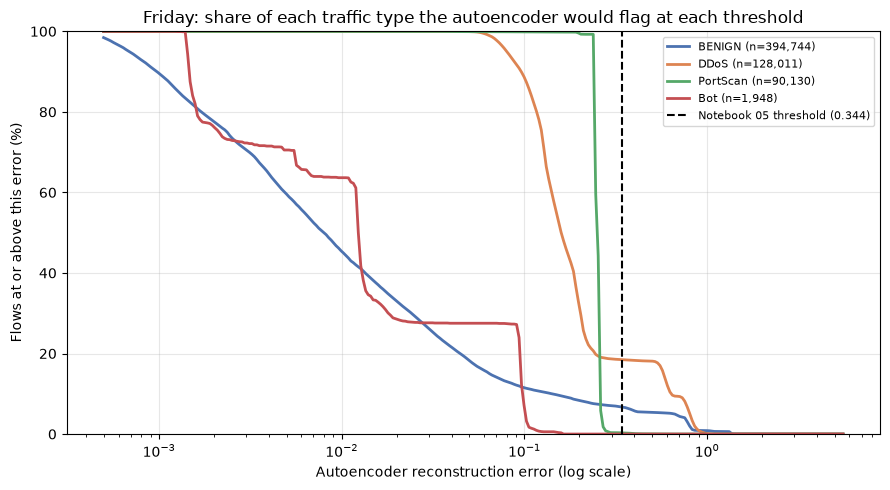

In [9]:
grid = np.logspace(np.log10(np.percentile(ae_error[idx_fri], 1)), np.log10(ae_error[idx_fri].max()), 300)
fig, ax = plt.subplots(figsize=(9, 5))
for lab, colour in [("BENIGN", "#4C72B0"), ("DDoS", "#DD8452"), ("PortScan", "#55A868"), ("Bot", "#C44E52")]:
    s = np.sort(ae_error[idx_fri][labels[idx_fri] == lab])
    if len(s):
        above = 100 * (1 - np.searchsorted(s, grid, side="left") / len(s))
        ax.plot(grid, above, label=f"{lab} (n={len(s):,})", color=colour, linewidth=2)
thr = thresholds.loc["Friday", "ae"]
ax.axvline(thr, color="black", linestyle="--", label=f"Notebook 05 threshold ({thr:.3f})")
ax.set_xscale("log"); ax.set_ylim(0, 100)
ax.set_xlabel("Autoencoder reconstruction error (log scale)")
ax.set_ylabel("Flows at or above this error (%)")
ax.set_title("Friday: share of each traffic type the autoencoder would flag at each threshold")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/06_ae_share_above_threshold.png", dpi=200); plt.show()

**What this shows** (`06_ae_share_above_threshold.png`): almost all PortScan flows have errors in a narrow band between about 0.2 and 0.26, just below the threshold of 0.344, so the autoencoder does see them as more unusual than most benign traffic, but not quite enough. About 80% of DDoS flows sit between 0.1 and 0.3 and about 18% above the threshold. Bot flows fall inside the benign range, which is why no model detects them. About 7% of benign flows are above the threshold (the 6.7% false positive rate). Moving the line left catches more attacks but adds false alarms (Section 5). Choosing the line from this chart would use Friday's labels, so it is shown as an analysis of the trade-off, not as a tuned result. This is the recommended chart for the presentation's results slide.

## 10. Save the run configuration

In [10]:
config = {"notebook": "06_hybrid_triage", "data_fingerprint": fingerprint, "capacities": CAPACITIES,
          "main_capacity": MAIN_CAPACITY, "queue_saved_per_day": QUEUE_SAVE, "top_features": TOP_FEATURES,
          "tiers": {"P1": "XGBoost >= 0.5 and autoencoder >= threshold", "P2": "XGBoost only",
                    "P3": "autoencoder only", "P4": "neither"},
          "numpy_vs_pytorch_max_relative_difference": float(max_diff),
          "versions": {"python": platform.python_version(), "xgboost": xgb.__version__,
                       "sklearn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__,
                       "matplotlib": matplotlib.__version__}}
with open(f"{OUT_DIR}/06_run_config.json", "w") as fh:
    json.dump(config, fh, indent=2)
print("Done.")

Done.


## Summary of Notebook 06

- The NumPy autoencoder reproduces the Notebook 05 model, and every queued alert now carries an explanation from each model.
- Ranking alerts against analyst capacity is more useful than fixed thresholds: XGBoost's top 1,000 Friday flows contain 879 real attacks, although only 255 crossed its 0.5 threshold.
- No ranking wins every day. The autoencoder ranking is best on Wednesday (968 of 1,000), XGBoost's on Thursday (908) and Friday (879), and the hybrid tiers are close to the best on Wednesday and Thursday but weak on Friday (257) because of benign drift.
- The a-priori assumption that agreement of both models (P1) is the strongest evidence was not supported.
- Friday's false alarms are driven mainly by URG Flag Count, a concrete source of drift.
- These findings shape the dashboard: it should let the analyst choose the ranking and the daily capacity, and show the explanation behind each alert.

**Questions to be ready for**
- *Why did the hybrid not beat XGBoost on Friday?* Because Friday's most unusual flows are benign traffic that changed, and the P3 tier put them high. The tier rule was fixed before testing, and changing it now would be tuning on the test data.
- *Why rank instead of using a threshold?* A SOC has a fixed number of alerts it can investigate. Ranking guarantees the most suspicious flows are seen first, whatever the threshold.
- *Are the explanations reliable?* They show what drove each model's score, checked against normal values, but they are not proof of cause; related features can share credit. They tell the analyst where to look first.